# Module 10 Assignment: Multidimensional Data & GroupBy
**CS 5045: Computation for the Data Sciences**

**Name:** Nick Freberg

---

Complete each section below by filling in the blanks marked `__________` or writing your answer where indicated. Section 5 (Code From Scratch) has no blanks — you write the full solution yourself. Run all cells top to bottom and make sure there are no errors. Commit and push this notebook (`hw10.ipynb`) to your fork on GitHub. No Canvas upload needed.

**Dataset:** `data.csv`, retail sales data: region, product_category, quarter, units_sold, revenue. The file is in the `Datasets/` folder one level up from this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset once at the top; all sections use this DataFrame.
df = pd.read_csv("data.csv")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(df.head())

Shape: 272 rows x 5 columns
      region product_category quarter  units_sold  revenue
0  Northeast      Electronics      Q1          52     8952
1  Northeast      Electronics      Q1         104    16475
2  Northeast      Electronics      Q1          71    12101
3  Northeast      Electronics      Q2         156    25327
4  Northeast      Electronics      Q2          72    12067


---
## Section 1: Load and Basic GroupBy

In [2]:
# 1a. AGGREGATE: compute the total revenue for each region.
#     Fill in the groupby column name and the aggregation function.
#     Store the result in by_region.

by_region = df.groupby("region")["revenue"].sum()
print("Total revenue by region:")
print(by_region)
# Expected (alphabetical order):
#   Midwest      628884
#   Northeast    784196
#   Southeast    620934
#   West         908743

Total revenue by region:
region
Midwest      628884
Northeast    784196
Southeast    620934
West         908743
Name: revenue, dtype: int64


In [5]:
# 1b. Which region had the highest total revenue?
#     Use by_region and .idxmax() to find the region name.
#     Store the result in top_region.

top_region = by_region.idxmax()
print("Region with highest revenue:", top_region)
# Expected: West

Region with highest revenue: West


In [6]:
# 1c. How many units were sold in total in the Southeast region?
#     Group by region, select units_sold, sum, then index the result
#     with ["Southeast"].
#     Store the result in southeast_units.

southeast_units = df.groupby("region")["units_sold"].sum()["Southeast"]
print("Southeast total units sold:", southeast_units)
# Expected: 7798

Southeast total units sold: 7798


---
## Section 2: Multiple Aggregation Functions with .agg()

In [8]:
# 2a. AGGREGATE: compute a summary table grouped by region.
#     Use .agg() to include THREE named statistics:
#       - mean_revenue  = mean of the revenue column
#       - total_units   = sum of the units_sold column
#       - num_records   = count of the revenue column
#
#     Fill in the function name strings (e.g., 'mean', 'sum', 'count').
#     Store the result in region_summary.

region_summary = df.groupby("region").agg(
    mean_revenue = ("revenue",    "mean"),
    total_units  = ("units_sold", "sum"),
    num_records  = ("revenue",    "count")
)
print("Region summary:")
print(region_summary)
# Expected (Midwest row):
#   mean_revenue: 9675.14
#   total_units:  7241
#   num_records:  65

Region summary:
           mean_revenue  total_units  num_records
region                                           
Midwest     9675.138462         7241           65
Northeast  11365.159420         9576           69
Southeast   9267.671642         7798           67
West       12799.197183        10969           71


In [9]:
# 2b. Convert region_summary to a flat DataFrame so that "region" becomes
#     a regular column instead of the row index.
#     Store the result in summary_flat.

summary_flat = region_summary.reset_index()
print("Flat summary (first 2 rows):")
print(summary_flat.head(2))
# Expected: "region" appears as a column, not as the index label

Flat summary (first 2 rows):
      region  mean_revenue  total_units  num_records
0    Midwest   9675.138462         7241           65
1  Northeast  11365.159420         9576           69


---
## Section 3: Grouped Bar Chart

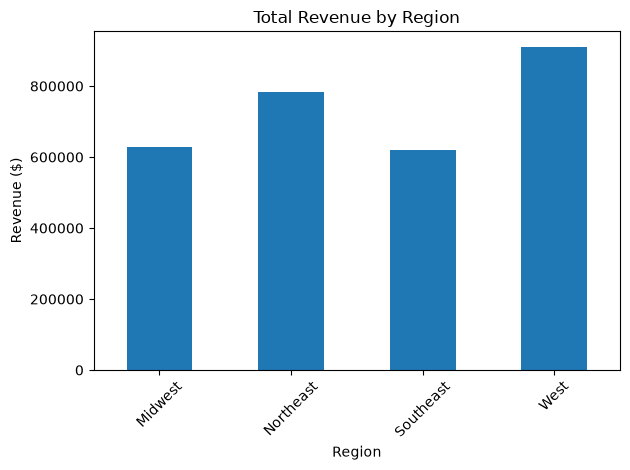

In [10]:
# 3a. COMMUNICATE: create a bar chart showing total revenue by region.
#
#     Step 1: compute total revenue by region (use by_region from Section 1,
#             or recompute it here -- either approach is fine).
#     Step 2: call .plot() on the result.
#             Fill in: kind=__________, title=__________, ylabel=__________
#
#     The chart should have:
#       - kind: "bar"
#       - title: "Total Revenue by Region"
#       - ylabel: "Revenue ($)"

by_region.plot(
    kind="bar",
    title="Total Revenue by Region",
    ylabel="Revenue ($)"
)
plt.xlabel("Region")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

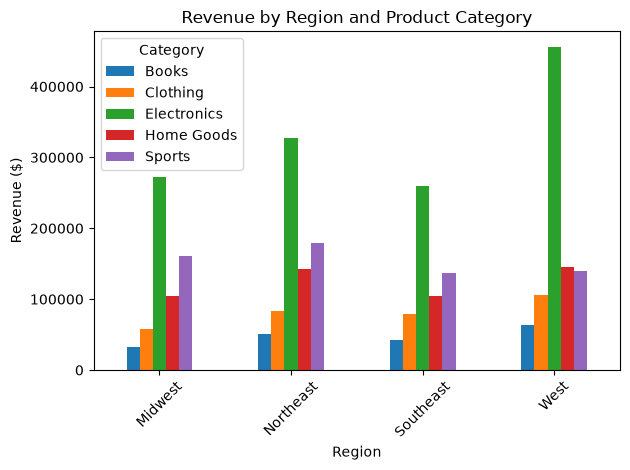

In [11]:
# 3b. Grouped bar chart: revenue by region AND product category.
#
#     Step 1: group by BOTH region and product_category, sum revenue,
#             then call .unstack() to pivot product_category into columns.
#     Step 2: call .plot(kind='bar') on the pivot result.
#
#     Fill in the two groupby column names.

pivot_cat = (
    df.groupby(["region", "product_category"])["revenue"].sum()
    .unstack()
)
pivot_cat.plot(kind="bar")
plt.title("Revenue by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.legend(title="Category")
plt.tight_layout()
plt.show()
# Expected: a grouped bar chart with five bars per region (one per product category)

---
## Section 4: Multi-Level GroupBy

In [12]:
# 4a. AGGREGATE: compute total revenue grouped by BOTH region AND quarter.
#     Fill in the two groupby column names.
#     Store the result in by_region_quarter.

by_region_quarter = df.groupby(["region", "quarter"])["revenue"].sum()
print("Total revenue by region and quarter:")
print(by_region_quarter)
# Expected: 16 rows (4 regions x 4 quarters), revenue summed for each combination

Total revenue by region and quarter:
region     quarter
Midwest    Q1         110822
           Q2         167392
           Q3         164139
           Q4         186531
Northeast  Q1         120147
           Q2         221036
           Q3         205538
           Q4         237475
Southeast  Q1         117269
           Q2         150238
           Q3         142993
           Q4         210434
West       Q1         156044
           Q2         239654
           Q3         212885
           Q4         300160
Name: revenue, dtype: int64


In [13]:
# 4b. TRANSFORM: reshape the result into a pivot table using .unstack().
#     Fill in the groupby column names (same two as 4a).
#     Store the result in pivot.

pivot = (
    df.groupby(["region", "quarter"])["revenue"].sum()
    .unstack(fill_value=0)
)
print("Pivot table, revenue by region and quarter:")
print(pivot)
# Expected: 4 rows (regions), 4 columns (Q1, Q2, Q3, Q4)

Pivot table, revenue by region and quarter:
quarter        Q1      Q2      Q3      Q4
region                                   
Midwest    110822  167392  164139  186531
Northeast  120147  221036  205538  237475
Southeast  117269  150238  142993  210434
West       156044  239654  212885  300160


In [14]:
# 4c. Which region had the highest Q2 revenue?
#     Use pivot["Q2"].idxmax() to find the answer.
#     Fill in the column name.

top_q2_region = pivot["Q2"].idxmax()
print("Region with highest Q2 revenue:", top_q2_region)
# Expected: West

Region with highest Q2 revenue: West


---
## Section 5: Code From Scratch

No blanks this time. You get the question only — write the full code yourself, using as many cells or intermediate variables as you like. This composes two operations you already used earlier in this module: **Filter** (narrow to one region) and **Aggregate** (group by category, sum units_sold).

**Question:** Within the **Midwest** region only, which product category sold the **most** total units? Which sold the **fewest**?

In [17]:
# Write your own code below. No starter code or blanks are provided for this section.
#
# Compute total units_sold by product_category, filtered to the Midwest region only,
units_by_category = df[df["region"] == "Midwest"].groupby("product_category")["units_sold"].sum()
# then identify the category with the most units and the category with the fewest.
largest_category = units_by_category.idxmax()
smallest_category = units_by_category.idxmin()

print(f"Largest category: {largest_category} ({units_by_category[largest_category]} units)")
print(f"Smallest category: {smallest_category} ({units_by_category[smallest_category]} units)")

# Expected: Sports highest (1,810 units); Clothing lowest (1,214 units)

Largest category: Sports (1810 units)
Smallest category: Clothing (1214 units)


**Reflection (one sentence):** Electronics leads total *revenue* in every region, including the Midwest. Does it also lead total *units sold* in the Midwest? In one sentence, explain why the revenue leader and the units leader might not be the same category.

**Your answer:** While Electronics leads total revenue in the Midwest, it does not lead total units sold, because its items cost much more per unit, so it can sell fewer and still earn the most.

---
## Section 6: Interpret

Answer the two questions below in the Markdown cells provided. Write in plain English. Do not reference Python syntax. Explain what the numbers mean in the context of the retail sales data.

**6a.** Look at the `region_summary` table you created in Section 2 (or reprint it below).
In 2-3 sentences, describe what the group comparison reveals. Are there meaningful differences across regions? What does the variation in `mean_revenue` tell you about the business?

**Your answer:** The West leads with the highest mean revenue per record (about $12,800) and the most units sold, followed by the Northeast, while the Midwest and Southeast trail at roughly $9,300 to $9,700. Since each region has a similar number of records, these differences seem meaningful, with the West bringing in about 38% more revenue per sale than the Southeast. The variation also suggests that product mix matters as much as volume, because the Southeast sold more units than the Midwest but still had lower mean revenue, which points to more of its sales coming from lower-priced categories.

In [18]:
# Optional: reprint region_summary here for reference while you write your answer.
print(region_summary.sort_values("mean_revenue", ascending=False))

           mean_revenue  total_units  num_records
region                                           
West       12799.197183        10969           71
Northeast  11365.159420         9576           69
Midwest     9675.138462         7241           65
Southeast   9267.671642         7798           67


**6b.** Using the pivot table from Section 4, identify which region had the **lowest** total revenue in Q1 and which had the highest in Q4. Write 2-3 sentences explaining what might account for that difference. What questions would you want to investigate next to understand why those regions differ?

**Your answer:** The Midwest had the lowest total revenue in Q1 ($110,822), and the West had the highest in Q4 ($300,160), almost three times as much. Part of that gap is seasonal, since every region peaks in Q4 when Electronics sells at higher prices per unit, and the West already sells more Electronics than any other region, while Q1 is the slowest quarter everywhere. Next, I'd want to know whether the West's lead comes from more customers or higher prices, and why the Midwest starts the year so slowly compared to the others.